# Classificação de células com malária: EDA, divisão dos dados e experimentos

Projeto da disciplina SIN 393 – Introdução à Visão Computacional (2026), UFV Campus Rio Paranaíba.

Dataset: [Cell Images for Detecting Malaria](https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria) (Kaggle)

Este notebook baixa o dataset, faz a análise exploratória e a divisão estratificada em treino, validação e teste, define o pré-processamento com data augmentation e treina duas arquiteturas, ResNet-18 e MobileNetV2, com pesos pré-treinados na ImageNet e com pesos aleatórios, usando 10%, 25% e 100% do conjunto de treino. Os modelos são avaliados no conjunto de teste com métricas, matrizes de confusão, exemplos de erros e teste de McNemar.

Sumário
1. Configuração do ambiente (GPU)
2. Download do dataset
3. Carregando os dados
4. Análise exploratória
5. Divisão em treino, validação e teste
6. Pré-processamento e data augmentation
7. Configuração do modelo e hiperparâmetros
8. Experimentos: construção dos modelos, treinos com semente fixa, frações de dados, métricas, matrizes de confusão, análise de erros e exportação dos resultados
9. Curvas de aprendizado da primeira execução

In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive')
PASTA_PROJETO = '/content/drive/MyDrive/Experimentos_Divisao_Paciente'
os.makedirs(PASTA_PROJETO, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuração do ambiente
Antes de rodar, ative a GPU em **Ambiente de execução → Alterar tipo de ambiente de execução → T4 GPU**.
A célula abaixo confirma que a GPU está disponível (deve aparecer "Tesla T4").


In [ ]:
!nvidia-smi

Sat Nov 21 00:24:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Download do dataset
O download usa a API do Kaggle. O token fica guardado nos **Secrets** do Colab (ícone 🔑 na barra lateral) com o nome `KAGGLE_API_TOKEN` e o acesso ao notebook ativado.


In [ ]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [ ]:
!pip install -q kaggle
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria
!unzip -q cell-images-for-detecting-malaria.zip -d data

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:17<00:00, 41.5MB/s]



Conferindo a estrutura de pastas. Dentro de `data/cell_images` existem `Parasitized`, `Uninfected` e uma pasta `cell_images` aninhada, que é uma **cópia duplicada e deve ser ignorada**.

In [ ]:
!ls data
!ls data/cell_images

cell_images
cell_images  Parasitized  Uninfected


## 3. Carregando os dados
Listamos todas as imagens `.png` das duas classes em um DataFrame (caminho + rótulo), usando apenas `Parasitized` e `Uninfected`.

In [ ]:
import re
from pathlib import Path
import pandas as pd

BASE = Path("data/cell_images")
classes = ["Parasitized", "Uninfected"]

# 1. Carregar caminhos e rótulos (seu código original)
rows = []
for c in classes:
  for p in (BASE / c).glob("*.png"):  # ignora arquivos indesejados
    rows.append({"path": str(p), "label": c})

df = pd.DataFrame(rows)


# 2. ADIÇÃO: Função para extrair o ID do paciente do nome do arquivo
def extrair_patient_id(caminho_str):
  nome_arquivo = Path(caminho_str).name
  # Captura o padrão inicial como C100P61 ou C33P1
  match = re.match(r"^(C\d+P\d+|C\d+)", nome_arquivo)
  if match:
    return match.group(1)
  return nome_arquivo.split("_")[0]


# 3. Criar a coluna de IDs de pacientes
df["patient_id"] = df["path"].apply(extrair_patient_id)

# 4. Conferência dos dados
print(f"Total de imagens: {len(df)}")
print(f"Distribuição de rótulos:\n{df['label'].value_counts()}\n")
print(f"Total de pacientes únicos encontrados: {df['patient_id'].nunique()}")

Total de imagens: 27558
Distribuição de rótulos:
label
Parasitized    13779
Uninfected     13779
Name: count, dtype: int64

Total de pacientes únicos encontrados: 200


## 4. Análise exploratória (EDA)

### 4.1 Balanceamento das classes
Verificamos se as classes têm quantidades parecidas. Isso define quais métricas são confiáveis e se será preciso tratar desbalanceamento.

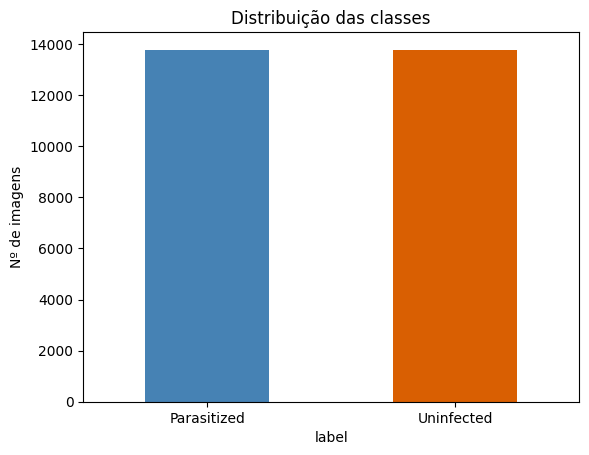

In [ ]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar", color=["#4682b4", "#d95f02"])
plt.title("Distribuição das classes")
plt.ylabel("Nº de imagens")
plt.xticks(rotation=0)
plt.show()

### 4.2 Exemplos de imagens
Quatro imagens aleatórias de cada classe (semente fixa). Esta figura pode ser usada na introdução do artigo.

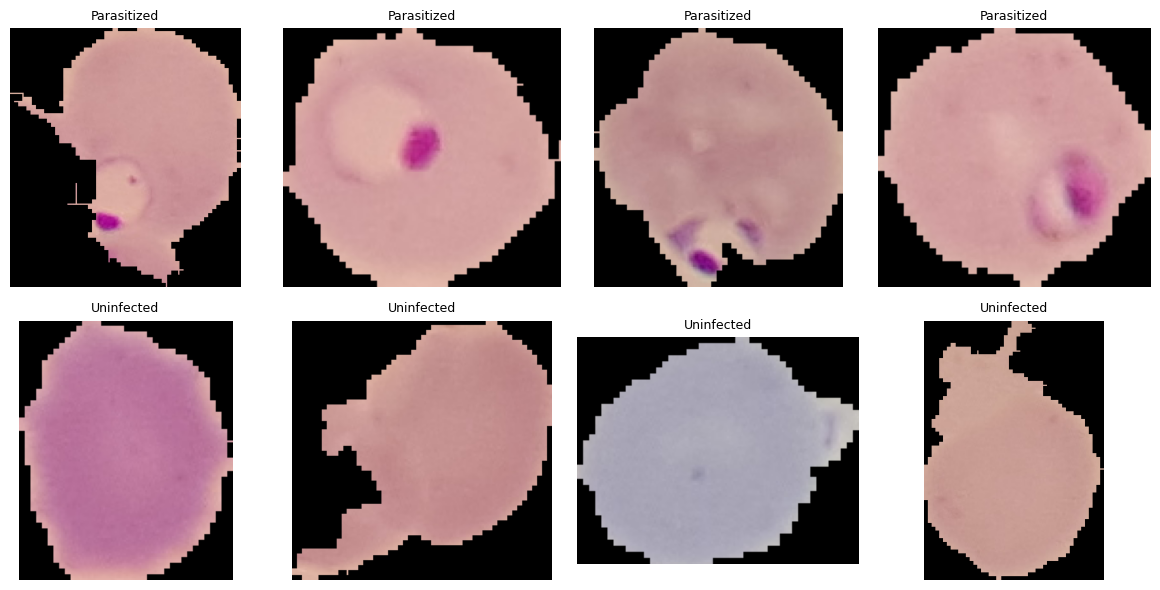

In [ ]:
from PIL import Image

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, c in enumerate(classes):
    amostra = df[df["label"] == c].sample(4, random_state=42)
    for j, (_, r) in enumerate(amostra.iterrows()):
        axes[i, j].imshow(Image.open(r["path"]))
        axes[i, j].set_title(c, fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig("amostras.png", dpi=150)
plt.show()

### 4.3 Tamanhos das imagens e arquivos corrompidos
As imagens têm resoluções diferentes, então será necessário um **resize** no pipeline. Também verificamos se há arquivos corrompidos.

In [ ]:
import numpy as np

tamanhos, corrompidas = [], []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            tamanhos.append(im.size)   # (largura, altura)
    except Exception:
        corrompidas.append(p)

larg = np.array([t[0] for t in tamanhos])
alt = np.array([t[1] for t in tamanhos])
print("Corrompidas:", len(corrompidas))
print("Largura  min/média/máx:", larg.min(), larg.mean().round(1), larg.max())
print("Altura   min/média/máx:", alt.min(), alt.mean().round(1), alt.max())

Corrompidas: 0
Largura  min/média/máx: 46 132.5 394
Altura   min/média/máx: 40 133.0 385


**Conclusões da EDA**
- 27.558 imagens, 13.779 por classe: dataset perfeitamente balanceado.
- Nenhuma imagem corrompida.
- Resolução variável (46–394 px de largura, 40–385 px de altura, média ≈ 133×133): será necessário redimensionar.

## 5. Divisão treino / validação / teste
Divisão **agrupada por ID de paciente** (70% treino / 15% validação / 15% teste) utilizando o `GroupShuffleSplit` da biblioteca `scikit-learn` com **semente fixa** (`SEED = 42`).

Esta abordagem substitui o `train_test_split` tradicional para evitar o vazamento de dados (*patient-level data leakage*), garantindo que todas as hemácias de um mesmo paciente permaneçamem um único conjunto. O conjunto de teste só será utilizado na avaliação final dos modelos.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

# 1. Primeiro Split: 70% treino e 30% temporário (validação + teste)
gss1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
train_idx, temp_idx = next(gss1.split(df, df["label"], groups=df["patient_id"]))

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# 2. Segundo Split: divide os 30% ao meio (15% validação e 15% teste)
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(temp_df, temp_df["label"], groups=temp_df["patient_id"]))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# 3. Exibir o resumo do particionamento
for nome, d in [("treino", train_df), ("validação", val_df), ("teste", test_df)]:
    n_pats = d["patient_id"].nunique()
    print(f"{nome}: {len(d)} imagens | {n_pats} pacientes | Rótulos: {d['label'].value_counts().to_dict()}")

treino: 20633 imagens | 140 pacientes | Rótulos: {'Parasitized': 10965, 'Uninfected': 9668}
validação: 3605 imagens | 30 pacientes | Rótulos: {'Uninfected': 2058, 'Parasitized': 1547}
teste: 3320 imagens | 30 pacientes | Rótulos: {'Uninfected': 2053, 'Parasitized': 1267}


#### Verificação de Vazamento de Dados (*Data Leakage Check*)
Confirmamos que não existe sobreposição de pacientes entre nenhum dos três conjuntos.

In [ ]:
train_pats = set(train_df["patient_id"])
val_pats = set(val_df["patient_id"])
test_pats = set(test_df["patient_id"])

print("Intersecção Treino x Validação:", len(train_pats.intersection(val_pats)))
print("Intersecção Treino x Teste:    ", len(train_pats.intersection(test_pats)))
print("Intersecção Validação x Teste: ", len(val_pats.intersection(test_pats)))

Intersecção Treino x Validação: 0
Intersecção Treino x Teste:     0
Intersecção Validação x Teste:  0


Salvamos a divisão por paciente em arquivos CSV dentro da pasta `splits_patient/` para que todos os experimentos utilizem **exatamente a mesma divisão sem vazamento**.

In [ ]:
import os

os.makedirs("splits_patient", exist_ok=True)
train_df.to_csv("splits_patient/train.csv", index=False)
val_df.to_csv("splits_patient/val.csv", index=False)
test_df.to_csv("splits_patient/test.csv", index=False)

# Backup local em zip (descomente caso precise baixar os CSVs)
# !zip -r splits_patient.zip splits_patient
# from google.colab import files
# files.download("splits_patient.zip")

## 6. Pré-processamento e data augmentation

Treino, validação e teste passam por *resize* e normalização (média e desvio do ImageNet, usados nos modelos pré-treinados). **Apenas o conjunto de treino recebe aumento de dados**, para que validação e teste meçam o desempenho em imagens sem alteração.

In [ ]:
import torch
from torchvision import transforms

IMG_SIZE = 224   # alternativa: 128 (treina mais rápido)
MEAN = [0.485, 0.456, 0.406]   # ImageNet
STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tf = transforms.Compose([   # validação e teste: sem aumento
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

### Justificativa das transformações

- **Flips horizontal e vertical e rotação:** células ao microscópio não têm orientação fixa, então essas variações são realistas e ensinam o modelo a não depender da posição.
- **Variação leve de brilho, contraste e saturação:** a iluminação e a coloração das lâminas variam entre amostras.
- **Matiz (hue) quase fixo (0,02):** a cor da coloração é pista diagnóstica (o parasita aparece com tom mais escuro), então alterá-la muito poderia destruir informação útil.
- **Sem recortes agressivos:** um recorte poderia remover o parasita e deixar a imagem com o rótulo errado.

### Dataset do PyTorch

A classe abaixo lê o caminho de cada imagem no DataFrame, abre a imagem, aplica a transformação e devolve o par (imagem, rótulo). Codificação: `Uninfected = 0` e `Parasitized = 1` (classe positiva).

In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}

class MalariaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, CLASS_TO_IDX[row["label"]]

train_ds = MalariaDataset(train_df, train_tf)
val_ds   = MalariaDataset(val_df, eval_tf)
test_ds  = MalariaDataset(test_df, eval_tf)
print(len(train_ds), len(val_ds), len(test_ds))

20633 3605 3320


### Visualizando o efeito do data augmentation

Uma imagem do treino, ao lado de 5 versões geradas pelas transformações aleatórias. Serve para conferir que o aumento não deforma demais as células.

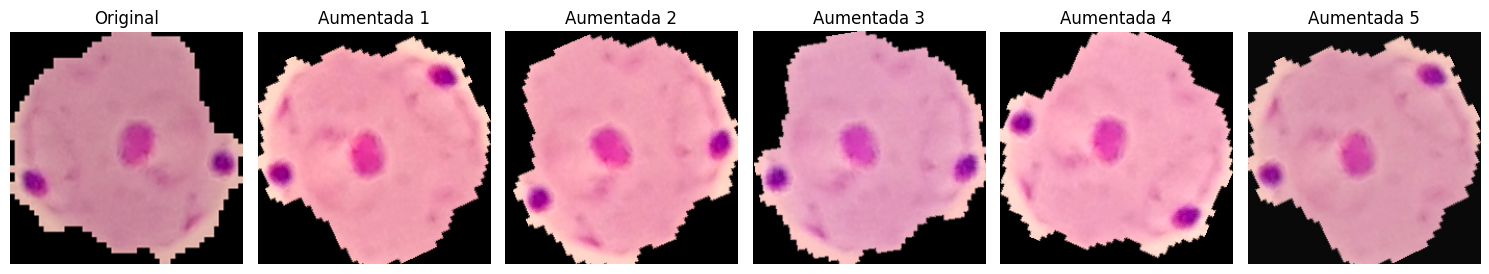

In [ ]:
import matplotlib.pyplot as plt

def desnormalizar(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()

row = train_df[train_df["label"] == "Parasitized"].iloc[0]
img = Image.open(row["path"]).convert("RGB")

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(img.resize((IMG_SIZE, IMG_SIZE)))
axes[0].set_title("Original")
for k in range(1, 6):
    axes[k].imshow(desnormalizar(train_tf(img)))
    axes[k].set_title(f"Aumentada {k}")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.savefig("augmentation.png", dpi=150)
plt.show()

### DataLoaders

Os DataLoaders entregam as imagens em lotes (*batches*). O treino é embaralhado a cada época; validação e teste, não.

In [ ]:
BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

x, y = next(iter(train_loader))
print(x.shape, y.shape)

torch.Size([64, 3, 224, 224]) torch.Size([64])


## 7. Configuração do modelo e hiperparâmetros
- **Dispositivo**: Verificação de disponibilidade de aceleração via GPU (`cuda`).
- **Modelo Base**: Teste inicial utilizando a arquitetura **ResNet-18** pré-treinada na ImageNet. A última camada linear (`fc`) foi adaptada para saída de **2 classes** (`Uninfected` e `Parasitized`).
- **Função de Perda**: `CrossEntropyLoss`, adequada para tarefas de classificação de imagens.
- **Otimizador**: `Adam` com taxa de aprendizado de $10^{-4}$.

### Funções de ciclo de treino e validação
- `train_epoch()`: Altera o modelo para o modo de treino (`model.train()`), executa o *forward pass*, calcula a perda, realiza a retropropagação (*backward pass*) e atualiza os pesos com `optimizer.step()`.
- `eval_epoch()`: Altera o modelo para o modo de avaliação (`model.eval()`) e desativa o cálculo de gradientes (`torch.no_grad()`) para medir o desempenho de validação com menor consumo de memória.

### Teste de validação do pipeline (*Sanity Check*)
Execução do treinamento por apenas **2 épocas** para validar o funcionamento do fluxo completo e evitar erros antes dos experimentos oficiais.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Definir o dispositivo (GPU se disponível)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Treinando no dispositivo: {device}")

# 2. Instanciar 1 modelo pré-treinado para teste (ex: ResNet18)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
# Ajustar a última camada para 2 classes (Uninfected e Parasitized)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

# 3. Definir a Função de Perda e o Otimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 4. Função de Treinamento por Época
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    all_preds, all_labels = [], []

    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    return epoch_loss, epoch_acc

# 5. Função de Validação por Época
def eval_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)
    return epoch_loss, epoch_acc

Treinando no dispositivo: cuda


In [ ]:
# Teste rápido de 2 épocas, só para validar o pipeline (registro, não roda mais)
NUM_EPOCHS = 2

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = eval_epoch(model, val_loader, criterion, device)

    print(f"Época {epoch+1}/{NUM_EPOCHS} | "
          f"Treino Loss: {train_loss:.4f} - Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.4f}")

Época 1/2 | Treino Loss: 0.1336 - Acc: 0.9506 | Val Loss: 0.0857 - Acc: 0.9750
Época 2/2 | Treino Loss: 0.0962 - Acc: 0.9661 | Val Loss: 0.0747 - Acc: 0.9739


## 08 – Função construtora dos modelos (build_model)

**Objetivo:** Cria uma função dinâmica em PyTorch capaz de instanciar as duas arquiteturas escolhidas (**ResNet-18** e **MobileNet_V2**), alternando entre pesos pré-treinados da ImageNet (*Transfer Learning*) e inicialização aleatória (treino do zero), ajustando a camada final de saída para 2 classes (`Uninfected` e `Parasitized`).

In [ ]:
import torch
import torch.nn as nn
from torchvision import models

def build_model(arch_name, pretrained=True, num_classes=2):
    """
    Instancia e adapta a arquitetura escolhida para o problema de 2 classes.
    """
    if arch_name == 'resnet18':
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        model = models.resnet18(weights=weights)
        # Adaptar a última camada totalmente conectada (fc)
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)

    elif arch_name == 'mobilenet_v2':
        weights = models.MobileNet_V2_Weights.DEFAULT if pretrained else None
        model = models.mobilenet_v2(weights=weights)
        # Adaptar a última camada do classificador
        num_ftrs = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(num_ftrs, num_classes)

    else:
        raise ValueError(f"Arquitetura '{arch_name}' não suportada.")

    return model

print("Função build_model definida com sucesso!")

Função build_model definida com sucesso!


### 08.1 Grade de configuração dos experimentos

A matriz experimental cruza duas arquiteturas, ResNet-18 e MobileNetV2, com duas condições de inicialização: pesos pré-treinados na ImageNet (transfer learning) ou pesos aleatórios (treino do zero). Todas as configurações usam a mesma divisão dos dados, o mesmo data augmentation, o otimizador Adam, lote de 64 imagens e 10 épocas.

A taxa de aprendizado é o único outro parâmetro que muda. Os modelos pré-treinados usam 1e-4, para ajustar os pesos sem destruir o que já aprenderam. Os modelos treinados do zero usam 1e-3, porque partem de pesos aleatórios e toleram passos maiores. Como a taxa muda junto com a inicialização, essa comparação mede duas receitas de treino e não isola o efeito dos pesos. Esse efeito não foi separado nos experimentos, e isso limita a conclusão sobre o papel isolado dos pesos pré-treinados.

- A-PT: ResNet-18 com transfer learning, taxa de aprendizado 1e-4
- A-ZERO: ResNet-18 treinada do zero, taxa de aprendizado 1e-3
- B-PT: MobileNetV2 com transfer learning, taxa de aprendizado 1e-4
- B-ZERO: MobileNetV2 treinada do zero, taxa de aprendizado 1e-3

In [ ]:
# Parâmetros gerais
NUM_EPOCHS = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Grade de experimentos: 2 arquiteturas x 2 inicializações
experiments = [
    {'code': 'A-PT',   'arch': 'resnet18',     'pretrained': True,  'lr': 1e-4},
    {'code': 'A-ZERO', 'arch': 'resnet18',     'pretrained': False, 'lr': 1e-3},
    {'code': 'B-PT',   'arch': 'mobilenet_v2', 'pretrained': True,  'lr': 1e-4},
    {'code': 'B-ZERO', 'arch': 'mobilenet_v2', 'pretrained': False, 'lr': 1e-3},
]

print(f"Dispositivo: {device}")
print(f"{len(experiments)} experimentos carregados, {NUM_EPOCHS} épocas cada.")

Dispositivo: cuda
4 experimentos carregados, 10 épocas cada.


### 08.2 Execução com semente fixa, pesos salvos e avaliação no teste

Esta etapa roda os quatro experimentos com a semente fixa em 42. Em cada um, os pesos da época com menor loss de validação são salvos, e esses pesos são usados uma única vez no conjunto de teste. As previsões ficam em `results/test_preds_*.csv`, e o histórico de treino em `results/history_*.csv`.

In [ ]:
import os, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from google.colab import drive

# 1. Monta o Drive e define as pastas permanentes
drive.mount('/content/drive')
BASE_DIR= '/content/drive/MyDrive/Experimentos_Divisao_Paciente'
RESULTS_DIR = os.path.join(BASE_DIR, "results")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def run_experiment(exp, seed=42, frac=1.0, num_epochs=10):
    tag = f"{exp['code']}_f{int(frac*100)}_s{seed}"

    best_ckpt_path = os.path.join(CKPT_DIR, f"{tag}.pt")
    resume_ckpt_path = os.path.join(CKPT_DIR, f"{tag}_last.pt")
    hist_path = os.path.join(RESULTS_DIR, f"history_{tag}.csv")
    preds_path = os.path.join(RESULTS_DIR, f"test_preds_{tag}.csv")

    # 2. SE JÁ TERMINOU TUDO: pula o experimento e lê o resultado salvo
    if os.path.exists(preds_path):
        test_out = pd.read_csv(preds_path)
        acc = (test_out['y_true'] == test_out['y_pred']).mean()
        print(f"[PULADO] {tag} já concluído no Drive | acurácia no teste: {acc:.4f}")
        return

    set_seed(seed)

    # Fração estratificada do treino (frac=1.0 usa tudo)
    if frac < 1.0:
        sub_df, _ = train_test_split(train_df, train_size=frac,
                                     stratify=train_df["label"], random_state=seed)
    else:
        sub_df = train_df
    g = torch.Generator()
    g.manual_seed(seed)
    tr_loader = DataLoader(MalariaDataset(sub_df, train_tf), batch_size=BATCH_SIZE,
                           shuffle=True, num_workers=2, generator=g)

    model = build_model(exp["arch"], pretrained=exp["pretrained"]).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=exp["lr"])

    start_epoch = 1
    best_val_loss = float("inf")
    rows = []

    # 3. SE CAIU NO MEIO DO TREINO: recupera a última época salva no Drive
    if os.path.exists(resume_ckpt_path):
        checkpoint = torch.load(resume_ckpt_path, map_location=device)
        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        start_epoch = checkpoint["epoch"] + 1
        best_val_loss = checkpoint["best_val_loss"]
        rows = checkpoint["rows"]
        print(f"[RETOMANDO] {tag} a partir da época {start_epoch:02d}...")

    # 4. Loop de treinamento
    for epoch in range(start_epoch, num_epochs + 1):
        tl, ta = train_epoch(model, tr_loader, criterion, optimizer, device)
        vl, va = eval_epoch(model, val_loader, criterion, device)
        rows.append({"epoch": epoch, "train_loss": tl, "train_acc": ta,
                     "val_loss": vl, "val_acc": va})

        if vl < best_val_loss:
            best_val_loss = vl
            torch.save(model.state_dict(), best_ckpt_path)

        # Salva o estado completo a cada época para retomada em caso de queda
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "rows": rows
        }, resume_ckpt_path)

        print(f"{tag} | época {epoch:02d} | treino {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f}")

    # Salva histórico final no Drive
    hist = pd.DataFrame(rows)
    hist["experiment"] = exp["code"]
    hist["frac"] = frac
    hist["seed"] = seed
    hist.to_csv(hist_path, index=False)

    # Avaliação única no teste, com os pesos da melhor época
    model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
    model.eval()
    preds, probs = [], []
    with torch.no_grad():
        for x, _ in test_loader:
            out = model(x.to(device))
            probs.extend(torch.softmax(out, 1)[:, 1].cpu().numpy())
            preds.extend(out.argmax(1).cpu().numpy())

    test_out = test_df.reset_index(drop=True).copy()
    test_out["y_true"] = test_out["label"].map(CLASS_TO_IDX)
    test_out["y_pred"] = preds
    test_out["prob_parasitized"] = probs
    test_out.to_csv(preds_path, index=False)
    print(f"{tag} | acurácia no teste: {(test_out['y_true'] == test_out['y_pred']).mean():.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import time
for exp in experiments:
    t0 = time.time()
    run_experiment(exp, seed=42)
    print(f"Tempo de {exp['code']}: {(time.time() - t0)/60:.1f} min\n")

A-PT_f100_s42 | época 01 | treino 0.1357/0.9506 | val 0.0853/0.9714
A-PT_f100_s42 | época 02 | treino 0.0984/0.9658 | val 0.0890/0.9692
A-PT_f100_s42 | época 03 | treino 0.0908/0.9687 | val 0.0931/0.9662
A-PT_f100_s42 | época 04 | treino 0.0834/0.9700 | val 0.0699/0.9756
A-PT_f100_s42 | época 05 | treino 0.0812/0.9717 | val 0.0815/0.9756
A-PT_f100_s42 | época 06 | treino 0.0772/0.9726 | val 0.0722/0.9742
A-PT_f100_s42 | época 07 | treino 0.0759/0.9729 | val 0.0688/0.9759
A-PT_f100_s42 | época 08 | treino 0.0732/0.9745 | val 0.0671/0.9789
A-PT_f100_s42 | época 09 | treino 0.0687/0.9747 | val 0.0655/0.9795
A-PT_f100_s42 | época 10 | treino 0.0691/0.9755 | val 0.0733/0.9703
A-PT_f100_s42 | acurácia no teste: 0.9720
Tempo de A-PT: 28.3 min

A-ZERO_f100_s42 | época 01 | treino 0.2899/0.8748 | val 0.1392/0.9648
A-ZERO_f100_s42 | época 02 | treino 0.1551/0.9505 | val 0.1090/0.9662
A-ZERO_f100_s42 | época 03 | treino 0.1492/0.9519 | val 0.1115/0.9681
A-ZERO_f100_s42 | época 04 | treino 0.1418/

100%|██████████| 13.6M/13.6M [00:00<00:00, 121MB/s]


B-PT_f100_s42 | época 01 | treino 0.1695/0.9413 | val 0.0904/0.9728
B-PT_f100_s42 | época 02 | treino 0.1035/0.9635 | val 0.0751/0.9753
B-PT_f100_s42 | época 03 | treino 0.0931/0.9677 | val 0.0797/0.9725
B-PT_f100_s42 | época 04 | treino 0.0867/0.9701 | val 0.0737/0.9748
B-PT_f100_s42 | época 05 | treino 0.0783/0.9716 | val 0.0772/0.9748
B-PT_f100_s42 | época 06 | treino 0.0735/0.9738 | val 0.0782/0.9745
B-PT_f100_s42 | época 07 | treino 0.0709/0.9742 | val 0.0749/0.9742
B-PT_f100_s42 | época 08 | treino 0.0702/0.9747 | val 0.0755/0.9764
B-PT_f100_s42 | época 09 | treino 0.0664/0.9756 | val 0.0752/0.9756
B-PT_f100_s42 | época 10 | treino 0.0615/0.9775 | val 0.0790/0.9745
B-PT_f100_s42 | acurácia no teste: 0.9681
Tempo de B-PT: 29.0 min

B-ZERO_f100_s42 | época 01 | treino 0.2642/0.8931 | val 0.1364/0.9670
B-ZERO_f100_s42 | época 02 | treino 0.1569/0.9500 | val 0.1394/0.9675
B-ZERO_f100_s42 | época 03 | treino 0.1539/0.9488 | val 0.1039/0.9659
B-ZERO_f100_s42 | época 04 | treino 0.1463/

### 08.3 Efeito da quantidade de dados de treino

Para avaliar se o transfer learning ajuda mais quando há poucos dados, os quatro experimentos são repetidos com 10% e 25% do conjunto de treino, amostrados de forma estratificada com a mesma semente. Validação e teste não mudam. Como o número de épocas é o mesmo, os modelos treinados com menos dados recebem menos atualizações de pesos, e isso precisa ser levado em conta na discussão.

In [ ]:
for exp in experiments:
    for frac in [0.10, 0.25]:
        t0 = time.time()
        run_experiment(exp, seed=42, frac=frac)
        print(f"Tempo de {exp['code']} com {int(frac*100)}%: {(time.time() - t0)/60:.1f} min\n")

[PULADO] A-PT_f10_s42 já concluído no Drive | acurácia no teste: 0.9645
Tempo de A-PT com 10%: 0.0 min

[PULADO] A-PT_f25_s42 já concluído no Drive | acurácia no teste: 0.9636
Tempo de A-PT com 25%: 0.0 min

[RETOMANDO] A-ZERO_f10_s42 a partir da época 08...
A-ZERO_f10_s42 | época 08 | treino 0.1843/0.9350 | val 0.1683/0.9598
A-ZERO_f10_s42 | época 09 | treino 0.1805/0.9404 | val 0.1305/0.9653
A-ZERO_f10_s42 | época 10 | treino 0.1737/0.9438 | val 0.1179/0.9648
A-ZERO_f10_s42 | acurácia no teste: 0.9554
Tempo de A-ZERO com 10%: 2.0 min

A-ZERO_f25_s42 | época 01 | treino 0.7132/0.6270 | val 0.7540/0.5739
A-ZERO_f25_s42 | época 02 | treino 0.3382/0.8641 | val 0.1939/0.9492
A-ZERO_f25_s42 | época 03 | treino 0.1938/0.9387 | val 0.1839/0.9656
A-ZERO_f25_s42 | época 04 | treino 0.1671/0.9444 | val 0.1239/0.9614
A-ZERO_f25_s42 | época 05 | treino 0.1719/0.9440 | val 0.1200/0.9642
A-ZERO_f25_s42 | época 06 | treino 0.1534/0.9506 | val 0.1199/0.9662
A-ZERO_f25_s42 | época 07 | treino 0.1509/0

### 08.4 Métricas no conjunto de teste

Os quatro modelos treinados com 100% dos dados e semente 42 são avaliados no conjunto de teste, usando os pesos da época com menor loss de validação. A classe positiva é `Parasitized`, então precisão e recall se referem à detecção de células infectadas. O F1 agregado usa a média macro, que coincide com a ponderada porque as duas classes têm o mesmo número de imagens no teste (2.067 cada). Os falsos negativos, células infectadas classificadas como saudáveis, são o erro mais grave em um contexto de diagnóstico.

In [ ]:
import glob, os
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support

CODES = ["A-PT", "A-ZERO", "B-PT", "B-ZERO"]

def carregar(code, frac=100, seed=42):
    return pd.read_csv(os.path.join(RESULTS_DIR, f"test_preds_{code}_f{frac}_s{seed}.csv"))

linhas = []
for code in CODES:
    d = carregar(code)
    y, p = d["y_true"], d["y_pred"]
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[1], zero_division=0)
    _, _, f1_macro, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    linhas.append({
        "Configuração": code,
        "Acurácia": accuracy_score(y, p),
        "Precisão (Parasitized)": pr[0],
        "Recall (Parasitized)": rc[0],
        "F1 (Parasitized)": f1[0],
        "F1 macro": f1_macro,
        "Falsos negativos": fn,
        "Falsos positivos": fp,
    })

metricas = pd.DataFrame(linhas).set_index("Configuração")
print(metricas.round(4))
metricas.round(4).to_csv(os.path.join(RESULTS_DIR, "metricas_teste.csv"))

              Acurácia  Precisão (Parasitized)  Recall (Parasitized)  \
Configuração                                                           
A-PT            0.9720                  0.9600                0.9669   
A-ZERO          0.9623                  0.9657                0.9345   
B-PT            0.9681                  0.9708                0.9448   
B-ZERO          0.9620                  0.9672                0.9321   

              F1 (Parasitized)  F1 macro  Falsos negativos  Falsos positivos  
Configuração                                                                  
A-PT                    0.9634    0.9704                42                51  
A-ZERO                  0.9499    0.9599                83                42  
B-PT                    0.9576    0.9660                70                36  
B-ZERO                  0.9494    0.9595                86                40  


### 08.5 Matrizes de confusão

As matrizes mostram, para cada configuração, quantas células de cada classe foram classificadas corretamente e em qual classe foram confundidas. A diagonal principal contém os acertos.

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

CODES = ["A-PT", "A-ZERO", "B-PT", "B-ZERO"]

def carregar(code, frac=100, seed=42):
    return pd.read_csv(os.path.join(RESULTS_DIR, f"test_preds_{code}_f{frac}_s{seed}.csv"))

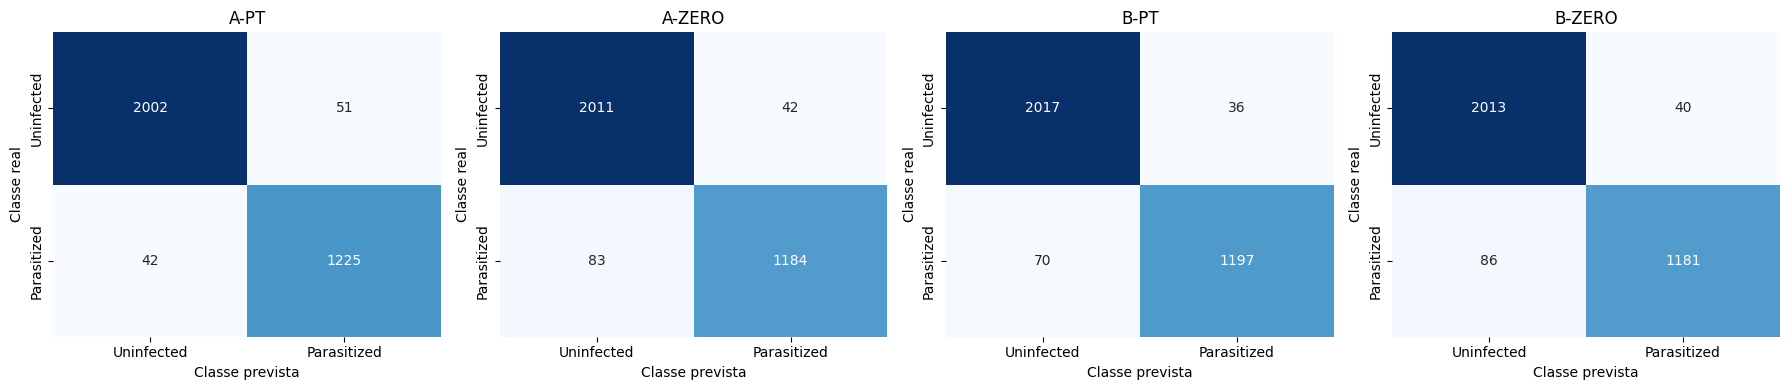

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

nomes = ["Uninfected", "Parasitized"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, code in zip(axes, CODES):
    d = carregar(code)
    cm = confusion_matrix(d["y_true"], d["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=nomes, yticklabels=nomes, ax=ax)
    ax.set_title(code)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "matrizes_confusao.png"), dpi=300)
plt.show()

### 08.6 Desempenho por quantidade de dados de treino

A acurácia no teste é comparada entre as frações de 10%, 25% e 100% do conjunto de treino, para cada configuração. Todos os modelos foram treinados por 10 épocas, então os que usam menos dados recebem menos atualizações de pesos, e isso influencia a comparação.

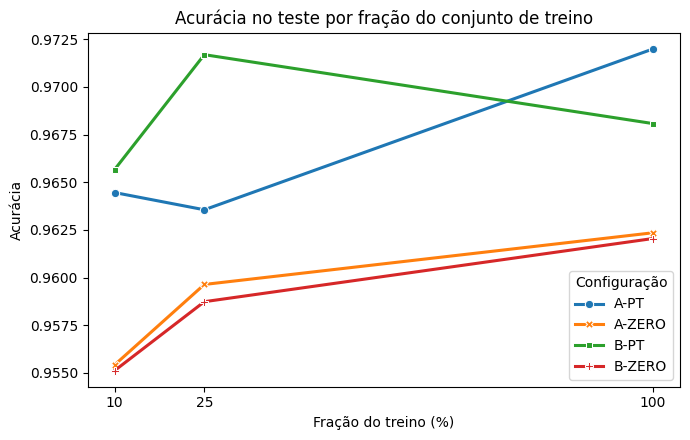

Fração do treino (%)     10      25      100
Configuração                                
A-PT                  0.9645  0.9636  0.9720
A-ZERO                0.9554  0.9596  0.9623
B-PT                  0.9657  0.9717  0.9681
B-ZERO                0.9551  0.9587  0.9620


In [ ]:
registros = []
for code in CODES:
    for frac in [10, 25, 100]:
        d = carregar(code, frac=frac)
        registros.append({"Configuração": code, "Fração do treino (%)": frac,
                          "Acurácia": (d["y_true"] == d["y_pred"]).mean()})
df_frac = pd.DataFrame(registros)

plt.figure(figsize=(7, 4.5))
sns.lineplot(data=df_frac, x="Fração do treino (%)", y="Acurácia", hue="Configuração",
             style="Configuração", markers=True, dashes=False, linewidth=2.2)
plt.xticks([10, 25, 100])
plt.title("Acurácia no teste por fração do conjunto de treino")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "acuracia_por_fracao.png"), dpi=300)
plt.show()

print(df_frac.pivot(index="Configuração", columns="Fração do treino (%)", values="Acurácia").round(4))

### 08.7 Análise qualitativa dos erros

A figura mostra exemplos de células classificadas corretamente e incorretamente pelo modelo A-PT no conjunto de teste. As imagens com erro foram sorteadas com semente fixa, sem escolher os casos mais difíceis, para que representem os erros em geral.

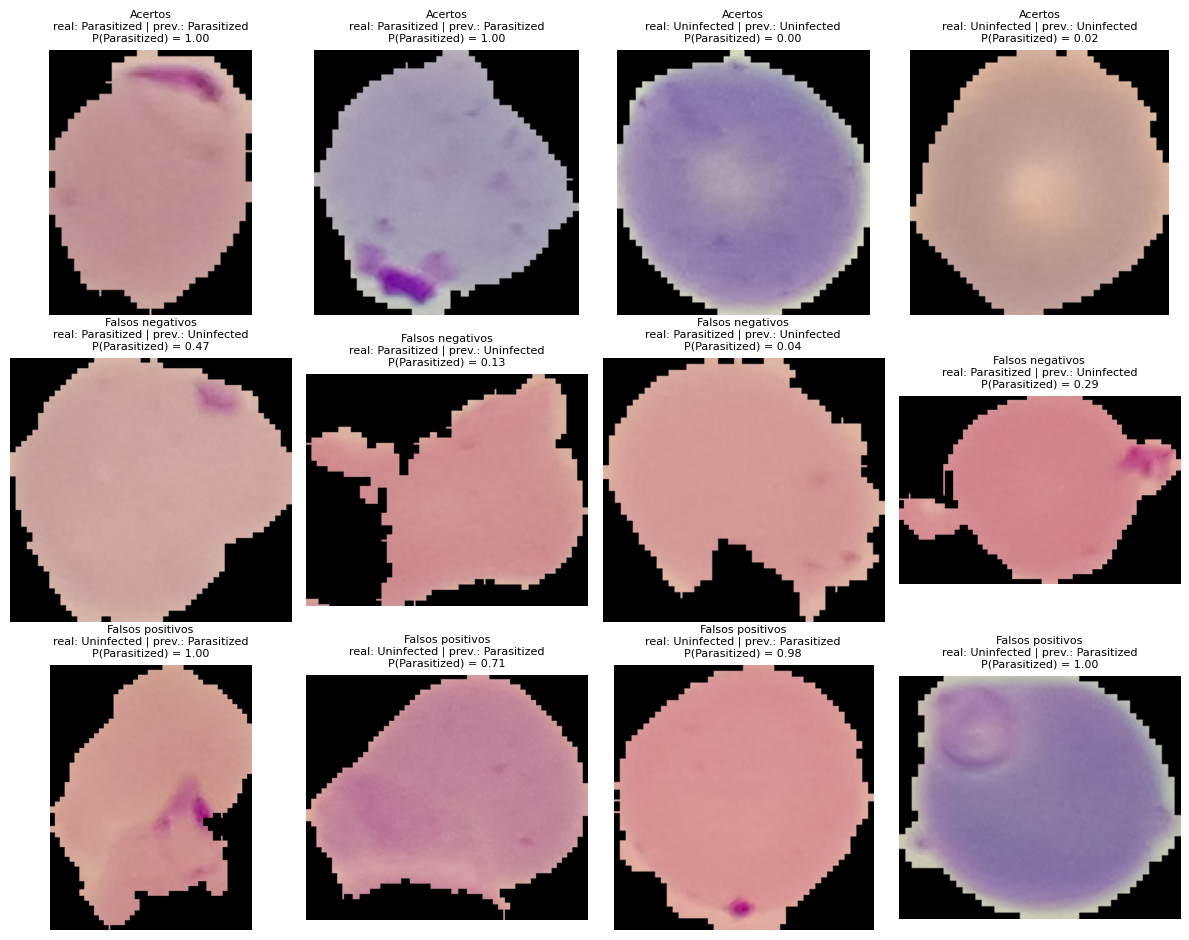

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

d = carregar("A-PT")
nome = {0: "Uninfected", 1: "Parasitized"}

fn = d[(d.y_true == 1) & (d.y_pred == 0)].sample(4, random_state=42)
fp = d[(d.y_true == 0) & (d.y_pred == 1)].sample(4, random_state=42)
ok = pd.concat([d[(d.y_true == 1) & (d.y_pred == 1)].sample(2, random_state=42),
                d[(d.y_true == 0) & (d.y_pred == 0)].sample(2, random_state=42)])

linhas = [("Acertos", ok), ("Falsos negativos", fn), ("Falsos positivos", fp)]
fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for i, (titulo, sub) in enumerate(linhas):
    for j, (_, r) in enumerate(sub.iterrows()):
        axes[i, j].imshow(Image.open(r["path"]).convert("RGB"))
        axes[i, j].set_title(f"{titulo}\nreal: {nome[r.y_true]} | prev.: {nome[r.y_pred]}\nP(Parasitized) = {r.prob_parasitized:.2f}", fontsize=8)
        axes[i, j].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "exemplos_erros.png"), dpi=300)
plt.show()

### 08.8 Teste de McNemar entre pares de modelos

Todos os modelos foram avaliados nas mesmas 4.134 imagens, então os acertos podem ser comparados imagem a imagem. O teste de McNemar considera apenas as imagens em que um modelo acertou e o outro errou e verifica se esse desequilíbrio é maior do que o esperado ao acaso (teste exato, bilateral). Como são quatro comparações, o nível de significância ajustado por Bonferroni é 0,0125.

In [ ]:
from scipy.stats import binomtest

def mcnemar(a, b):
    da, db = carregar(a), carregar(b)
    assert (da["path"] == db["path"]).all()
    ok_a = (da["y_true"] == da["y_pred"]).to_numpy()
    ok_b = (db["y_true"] == db["y_pred"]).to_numpy()
    so_a = int((ok_a & ~ok_b).sum())
    so_b = int((~ok_a & ok_b).sum())
    p = binomtest(so_a, so_a + so_b, 0.5).pvalue
    return {"Modelo A": a, "Modelo B": b, "Só A acertou": so_a, "Só B acertou": so_b, "p-valor": p}

pares = [("A-PT", "A-ZERO"), ("B-PT", "B-ZERO"), ("A-PT", "B-PT"), ("A-ZERO", "B-ZERO")]
tab_mcnemar = pd.DataFrame([mcnemar(a, b) for a, b in pares])
print(tab_mcnemar.round(4))
tab_mcnemar.round(4).to_csv(os.path.join(RESULTS_DIR, "mcnemar.csv"), index=False)

  Modelo A Modelo B  Só A acertou  Só B acertou  p-valor
0     A-PT   A-ZERO            71            39   0.0029
1     B-PT   B-ZERO            52            32   0.0375
2     A-PT     B-PT            43            30   0.1597
3   A-ZERO   B-ZERO            26            25   1.0000


### 08.09 Exportação dos resultados

Os históricos e as previsões no teste são compactados para download e versionados no repositório. Os pesos dos modelos (`checkpoints/`) não são enviados ao GitHub.

In [ ]:
!zip -rq results.zip "{RESULTS_DIR}"
from google.colab import files
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 09 – Visualização das curvas de aprendizado comparativas

**Objetivo:** Gerar os gráficos de evolução da Perda (*Loss*) e da Acurácia de Validação ao longo das épocas para comparar o desempenho entre as arquiteturas pré-treinadas (`A-PT`, `B-PT`) e as treinadas do zero (`A-ZERO`, `B-ZERO`).

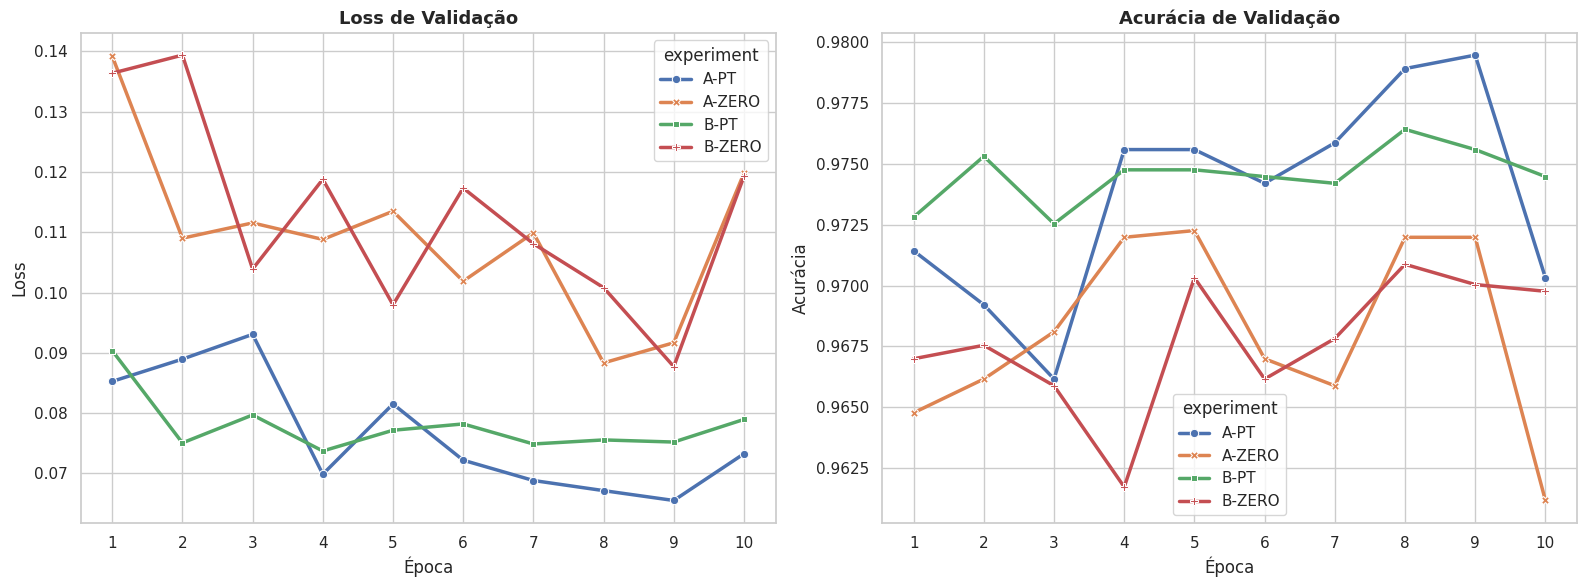

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

CODES = ["A-PT", "A-ZERO", "B-PT", "B-ZERO"]

# Carrega os históricos diretamente da pasta RESULTS_DIR no Drive
df_all = pd.concat([
    pd.read_csv(os.path.join(RESULTS_DIR, f"history_{c}_f100_s42.csv"))
    for c in CODES
], ignore_index=True)

# Painel com os 2 subplots (Loss e Acurácia)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Loss de Validação (corrigido com axes[0])
sns.lineplot(data=df_all, x='epoch', y='val_loss', hue='experiment',
             style='experiment', markers=True, dashes=False, linewidth=2.5, ax=axes[0])
axes[0].set_title('Loss de Validação', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Loss')
axes[0].set_xticks(range(1, df_all['epoch'].max() + 1))

# Gráfico 2: Acurácia de Validação
sns.lineplot(data=df_all, x='epoch', y='val_acc', hue='experiment',
             style='experiment', markers=True, dashes=False, linewidth=2.5, ax=axes[1])
axes[1].set_title('Acurácia de Validação', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Acurácia')
axes[1].set_xticks(range(1, df_all['epoch'].max() + 1))

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "curvas_aprendizado.png"), dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 09.1 – Ranking de Acurácia Final

**Objetivo:** Apresentar a comparação em formato de gráfico de barras com os percentuais finais alcançados por cada modelo.

/tmp/ipykernel_12000/1900679026.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(data=df_final, x='experiment', y='val_acc', palette=palette)


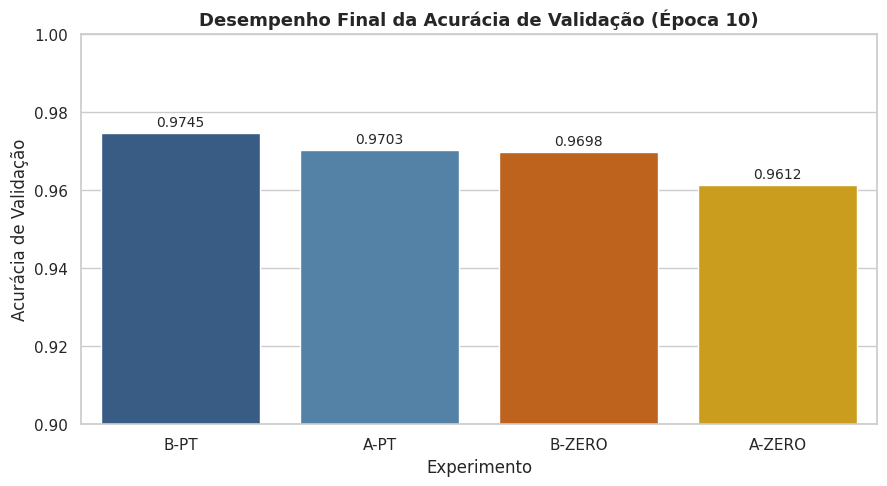

In [ ]:
# 1. Filtrar as métricas da última época (Época 10)
max_epoch = df_all['epoch'].max()
df_final = df_all[df_all['epoch'] == max_epoch].sort_values(by='val_acc', ascending=False)

# 2. Plotar o gráfico de barras
plt.figure(figsize=(9, 5))
palette = ['#2b5c8f', '#4682b4', '#d95f02', '#e6ab02']
barplot = sns.barplot(data=df_final, x='experiment', y='val_acc', palette=palette)

plt.title(f'Desempenho Final da Acurácia de Validação (Época {max_epoch})', fontsize=13, fontweight='bold')
plt.xlabel('Experimento')
plt.ylabel('Acurácia de Validação')
plt.ylim(0.90, 1.00)

# Adicionar os valores exatos sobre cada barra
for p in barplot.patches:
    barplot.annotate(f'{p.get_height():.4f}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                     textcoords='offset points')

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "ranking_acuracia_final.png"), dpi=300)
plt.show()

In [ ]:
import os; print(os.listdir('/content/drive/MyDrive/Experimentos_Divisao_Paciente'))

['checkpoints', 'results']


In [ ]:
import os
print(sorted([f for f in os.listdir(RESULTS_DIR) if f.startswith("test_preds_")]))

['test_preds_A-PT_f100_s42.csv', 'test_preds_A-PT_f10_s42.csv', 'test_preds_A-PT_f25_s42.csv', 'test_preds_A-ZERO_f100_s42.csv', 'test_preds_B-PT_f100_s42.csv', 'test_preds_B-ZERO_f100_s42.csv']
